# ERTH 2001 Lab 2: Using GPS Position Time Series to Monitor Plate Motion

This notebook reproduces Lab 2 from ERTH 2001 (Planet Earth) in Python. The lab was originally an Excel workbook of GPS position time series: plot how five California stations move north and east, measure a five-year rate in each direction, combine those components into a horizontal speed and a compass direction, and compare neighboring stations across the San Andreas fault. The same steps are followed here, one section at a time, so the concept each step was written to teach is the concept the code shows.

The position series and the five-year windows below are the ones from the completed Excel workbook. A final check cell loads those spreadsheet values and confirms that the Python results match them.

AI used: this notebook was built with help from an AI coding agent.


## Setup

A GPS station is a receiver fixed to bedrock. Each record in this lab is a position relative to a reference point, split into a **north** component and an **east** component, in millimeters. Four of the five stations are given as a 30-day average of that position; P294 is given as a daily position. All five series use the NAM08 reference frame, which is tied to the stable interior of the North American plate. In that frame, a station sitting still on stable North America should hover near zero, and a station being carried with the Pacific plate should drift relative to North America.

Over a chosen time window the change in each component is

$$\Delta N = N(t_\mathrm{end}) - N(t_\mathrm{start}), \qquad \Delta E = E(t_\mathrm{end}) - E(t_\mathrm{start}).$$

The lab converts those distances into rates by dividing by 5 years — the window length used in the spreadsheet, even when the exact decimal-date span is a few days short of five years:

$$v_N = \Delta N / 5\,\mathrm{yr}, \qquad v_E = \Delta E / 5\,\mathrm{yr}.$$

The horizontal speed is the hypotenuse of those two rates,

$$v = \sqrt{v_N^2 + v_E^2},$$

and the direction comes from the signs of $v_N$ and $v_E$ (northeast, northwest, southeast, or southwest). That is the same construction as drawing a north arrow, then an east–west arrow from its tip, then the diagonal from the origin.

The helpers below load the trimmed time series, compute that two-point rate, and draw the plots used in each part.


In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import FancyArrowPatch

DATADIR = Path("data")
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

# The completed spreadsheet divides every 5-year window by 5,
# even when the decimal-date span is a few days short of 5 years.
YEARS_FOR_RATE = 5.0

# Five-year windows used in the completed Excel workbook.
WINDOWS = {
    "BEMT": ("2006-01-06", "2011-01-01"),
    "SBCC": ("2006-01-01", "2010-12-27"),
    "CAND": ("2010-01-01", "2015-01-01"),
    "CARH": ("2010-01-01", "2015-01-01"),
    "P294": ("2010-01-01", "2015-01-01"),
}

# One color per station, reused in every figure.
STATION_COLORS = {
    "BEMT": "#2A6F97",
    "SBCC": "#C44536",
    "CAND": "#2E8B57",
    "CARH": "#D4A017",
    "P294": "#6B4C9A",
}

TITLE = dict(fontsize=13, fontweight="bold", color="#1a1a1a")


def load_positions():
    """Load the trimmed GPS series (one row per station per day)."""
    df = pd.read_csv(DATADIR / "positions.csv.gz", parse_dates=["date"])
    return df


def load_stations():
    """Load the station metadata taken from the workbook headers."""
    return pd.read_csv(DATADIR / "stations.csv")


def station_series(positions, station):
    """Return one station's rows, sorted by date."""
    out = positions.loc[positions["station"] == station].copy()
    return out.sort_values("date").reset_index(drop=True)


def interval_pair(df, start, end):
    """Return the start-row and end-row for an exact calendar date."""
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)
    s = df.loc[df["date"] == start]
    e = df.loc[df["date"] == end]
    if len(s) != 1 or len(e) != 1:
        raise ValueError(
            f"expected exactly one row at {start.date()} and {end.date()}, "
            f"got {len(s)} and {len(e)}"
        )
    return s.iloc[0], e.iloc[0]


def compass_direction(rate_n, rate_e):
    """Name the quadrant from the signs of the north and east rates."""
    ns = "north" if rate_n > 0 else ("south" if rate_n < 0 else None)
    ew = "east" if rate_e > 0 else ("west" if rate_e < 0 else None)
    if ns and ew:
        return ns + ew  # "northeast", "northwest", ...
    return ns or ew or "none"


def azimuth_from_north_deg(rate_n, rate_e):
    """Azimuth in degrees, clockwise from north (0° = north, 90° = east)."""
    return (math.degrees(math.atan2(rate_e, rate_n)) + 360.0) % 360.0


def motion_over_interval(df, station, start, end, years=YEARS_FOR_RATE):
    """Two-point rate for one station over a window, following the lab method.

    The east rate is signed: positive is east, negative is west. The
    original spreadsheet stores the east difference as an absolute
    value and records the compass direction separately.
    """
    first, last = interval_pair(df, start, end)
    dN = float(last["north_mm"] - first["north_mm"])
    dE = float(last["east_mm"] - first["east_mm"])
    rate_n = dN / years
    rate_e = dE / years
    total = math.hypot(rate_n, rate_e)
    dt = float(last["decimal_date"] - first["decimal_date"])
    return {
        "station": station,
        "start": pd.Timestamp(start).date().isoformat(),
        "end": pd.Timestamp(end).date().isoformat(),
        "start_decimal": float(first["decimal_date"]),
        "end_decimal": float(last["decimal_date"]),
        "dt_years": dt,
        "north_start": float(first["north_mm"]),
        "north_end": float(last["north_mm"]),
        "east_start": float(first["east_mm"]),
        "east_end": float(last["east_mm"]),
        "dN": dN,
        "dE": dE,
        "rate_n": rate_n,
        "rate_e": rate_e,
        "total": total,
        "direction": compass_direction(rate_n, rate_e),
        "azimuth_deg": azimuth_from_north_deg(rate_n, rate_e),
    }


def show_rates_table(results):
    """Display a readable table of two-point rates."""
    rows = []
    for r in results:
        rows.append({
            "Station": r["station"],
            "Window": f"{r['start']} to {r['end']}",
            "Span (yr)": r["dt_years"],
            "ΔN (mm)": r["dN"],
            "ΔE (mm)": r["dE"],
            "North rate (mm/yr)": r["rate_n"],
            "East rate (mm/yr)": r["rate_e"],
            "Total rate (mm/yr)": r["total"],
            "Direction": r["direction"],
            "Azimuth (°)": r["azimuth_deg"],
        })
    table = pd.DataFrame(rows)
    fmt = {
        "Span (yr)": "{:.4f}",
        "ΔN (mm)": "{:.4f}",
        "ΔE (mm)": "{:.4f}",
        "North rate (mm/yr)": "{:.4f}",
        "East rate (mm/yr)": "{:.4f}",
        "Total rate (mm/yr)": "{:.4f}",
        "Azimuth (°)": "{:.1f}",
    }
    display(table.style.format(fmt).hide(axis="index"))
    return table


def _shade_window(ax, result):
    ax.axvspan(result["start_decimal"], result["end_decimal"],
               color=STATION_COLORS[result["station"]], alpha=0.12, zorder=0)
    ax.axvline(result["start_decimal"], color="#666666", lw=0.6, ls="--")
    ax.axvline(result["end_decimal"], color="#666666", lw=0.6, ls="--")


def plot_timeseries(positions, results, filename, title):
    """Scatter of north and east vs decimal date, one row per station."""
    n = len(results)
    fig, axes = plt.subplots(n, 2, figsize=(11.6, 2.7 * n), sharex=True)
    if n == 1:
        axes = np.array([axes])
    for row, result in enumerate(results):
        df = station_series(positions, result["station"])
        color = STATION_COLORS[result["station"]]
        for col, component, ylabel in (
            (0, "north_mm", "North position (mm)"),
            (1, "east_mm", "East position (mm)"),
        ):
            ax = axes[row, col]
            ax.scatter(
                df["decimal_date"], df[component],
                s=6, c=color, alpha=0.45, linewidths=0, zorder=2,
            )
            _shade_window(ax, result)
            # Mark the two endpoints used for the rate.
            first, last = interval_pair(df, result["start"], result["end"])
            ax.scatter(
                [first["decimal_date"], last["decimal_date"]],
                [first[component], last[component]],
                s=32, c=color, edgecolors="#1a1a1a", linewidths=0.6, zorder=3,
            )
            ax.set_ylabel(ylabel)
            ax.grid(True, alpha=0.3)
            side = "North" if col == 0 else "East"
            ax.set_title(
                f"{result['station']} — {side}",
                fontsize=12, fontweight="bold", color="#1a1a1a",
            )
        axes[row, 0].text(
            0.02, 0.95,
            f"5-year window: {result['start']} to {result['end']}",
            transform=axes[row, 0].transAxes, ha="left", va="top",
            fontsize=8, color="#333333",
        )
    axes[-1, 0].set_xlabel("Decimal date")
    axes[-1, 1].set_xlabel("Decimal date")
    fig.suptitle(title, **TITLE, y=1.01)
    fig.tight_layout()
    out = FIGDIR / filename
    fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"saved {out}")


def plot_vectors(results, filename, title, scale_max=None):
    """Draw each station's north, east, and resultant arrows on a grid."""
    n = len(results)
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.6))
    if n == 1:
        axes = [axes]
    if scale_max is None:
        scale_max = max(r["total"] for r in results) * 1.25
    # Same numeric limit on every panel so arrow lengths compare directly.
    lim = max(10.0, math.ceil(scale_max / 5.0) * 5.0)
    for ax, result in zip(axes, results):
        vn, ve = result["rate_n"], result["rate_e"]
        color = STATION_COLORS[result["station"]]
        ax.axhline(0, color="#888888", lw=0.8)
        ax.axvline(0, color="#888888", lw=0.8)
        # Guide arrow: annual north-south movement from the origin.
        ax.annotate(
            "", xy=(0, vn), xytext=(0, 0),
            arrowprops=dict(arrowstyle="->", color="#555555", lw=1.4,
                            shrinkA=0, shrinkB=0),
        )
        # Guide arrow: annual east-west movement from the tip of the north arrow.
        ax.annotate(
            "", xy=(ve, vn), xytext=(0, vn),
            arrowprops=dict(arrowstyle="->", color="#555555", lw=1.4,
                            shrinkA=0, shrinkB=0),
        )
        # Resultant: origin to the end point of the east-west arrow.
        ax.annotate(
            "", xy=(ve, vn), xytext=(0, 0),
            arrowprops=dict(arrowstyle="-|>", color=color, lw=2.4,
                            mutation_scale=14, shrinkA=0, shrinkB=0),
        )
        ax.plot(ve, vn, "o", color=color, ms=5, zorder=4)
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
        ax.set_aspect("equal")
        ax.set_xlabel("East rate (mm/yr)")
        ax.set_ylabel("North rate (mm/yr)")
        ax.grid(True, alpha=0.3)
        ax.set_title(
            f"{result['station']}\n{result['total']:.2f} mm/yr {result['direction']}",
            fontsize=12, fontweight="bold", color="#1a1a1a",
        )
        # Component labels, kept off the arrows so a short vector stays readable.
        ax.text(
            1.6 if ve <= 0 else -1.6,
            0.5 * vn,
            f"{vn:+.2f}",
            ha="left" if ve <= 0 else "right",
            va="center",
            fontsize=8,
            color="#333333",
        )
        ax.text(
            0.5 * ve,
            vn + (2.2 if vn >= 0 else -2.2),
            f"{ve:+.2f}",
            ha="center",
            va="bottom" if vn >= 0 else "top",
            fontsize=8,
            color="#333333",
        )
    fig.suptitle(title, **TITLE, y=1.03)
    fig.tight_layout()
    out = FIGDIR / filename
    fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"saved {out}")


## The data

The original lab workbook is a multi-megabyte Excel file with a tab per station and a date-conversion formula on every row. This folder keeps a trimmed copy: `data/positions.csv.gz` has, for each day, the station id, the calendar date, the decimal date, and the north and east positions in millimeters. `data/stations.csv` has the header metadata — reference frame, coordinates when they were in the workbook, the official begin/end dates, and the range of the provided series. BEMT's header in the workbook lists a latitude but no longitude or elevation, so those two fields are left blank.


In [2]:
positions = load_positions()
stations = load_stations()

print(f"{len(positions)} daily samples across {positions['station'].nunique()} stations")
print("units of the north and east columns: millimeters (mm)")
print("reference frame (from every workbook header):")
print(" ", stations["reference_frame"].unique().tolist())
print()
print("Date range of the series in this folder")
print("(this is the range the lab works with; the header also lists a longer official record):")
summary = (
    positions.groupby("station", sort=False)
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        n_samples=("date", "size"),
    )
    .reset_index()
)
summary = summary.merge(
    stations[
        [
            "station",
            "station_name",
            "reference_frame",
            "latitude_deg",
            "longitude_deg",
            "elevation_m",
            "north_east_description",
            "header_begin_date",
            "header_end_date",
            "notes",
        ]
    ],
    on="station",
)
display(
    summary.style.format(
        {
            "first_date": lambda d: pd.Timestamp(d).date().isoformat(),
            "last_date": lambda d: pd.Timestamp(d).date().isoformat(),
            "latitude_deg": "{:.6f}",
            "longitude_deg": "{:.6f}",
            "elevation_m": "{:.3f}",
        },
        na_rep="—",
    ).hide(axis="index")
)


23995 daily samples across 5 stations
units of the north and east columns: millimeters (mm)
reference frame (from every workbook header):
  ['NAM08']

Date range of the series in this folder
(this is the range the lab works with; the header also lists a longer official record):


station,first_date,last_date,n_samples,station_name,reference_frame,latitude_deg,longitude_deg,elevation_m,north_east_description,header_begin_date,header_end_date,notes
BEMT,2006-01-06,2018-06-14,4543,BEMT_SCGN_CS2001,NAM08,34.000534,—,—,North/East 30-day average (mm),2001-11-15,2018-06-14,Longitude and elevation were not present in this station's workbook header.
SBCC,2006-01-01,2018-06-16,4550,SBCC_SCGN_CS1999,NAM08,33.553000,-117.661486,88.689,North/East 30-day average (mm),1999-11-08,2018-06-16,—
CAND,2004-01-01,2018-06-17,5260,CAND_SCGN_CN1999,NAM08,35.939352,-120.433697,568.402,North/East 30-day average (mm),1999-08-20,2018-06-17,—
CARH,2004-01-01,2018-06-17,5280,CARH_SCGN_CN2001,NAM08,35.888385,-120.430821,480.266,North/East 30-day average (mm),2001-08-09,2018-06-17,—
P294,2006-05-18,2018-04-26,4362,AlcaldeHlsCN2006,NAM08,36.123237,-120.439882,509.410,daily North/East (mm),2006-05-18,2018-10-01,—


The table is the first look the lab asks for: the calendar range of each series, the NAM08 reference frame, and the units (millimeters). NAM08 being fixed to stable North America means the motions we plot are already *relative to that plate's interior*, not to a global average. A number near zero is "not moving with respect to stable North America." A large northwest rate is "moving northwest relative to stable North America."


## Part 1 — Two stations in southern California

The San Andreas system is a northwest–southeast transform boundary. The lab starts with two GPS stations in southern California — Belle Mountain (BEMT, near Twentynine Palms) and Saddleback Community College (SBCC, near Mission Viejo) — and two simple starting ideas: that stations on opposite sides of a transform would move in opposite directions parallel to the boundary, or that they would move in the same direction parallel to the boundary.

The first practical step is a scatter plot of north and east against decimal date, the same columns the spreadsheet plots. The shaded band on each panel is the five-year window used later for the rate.


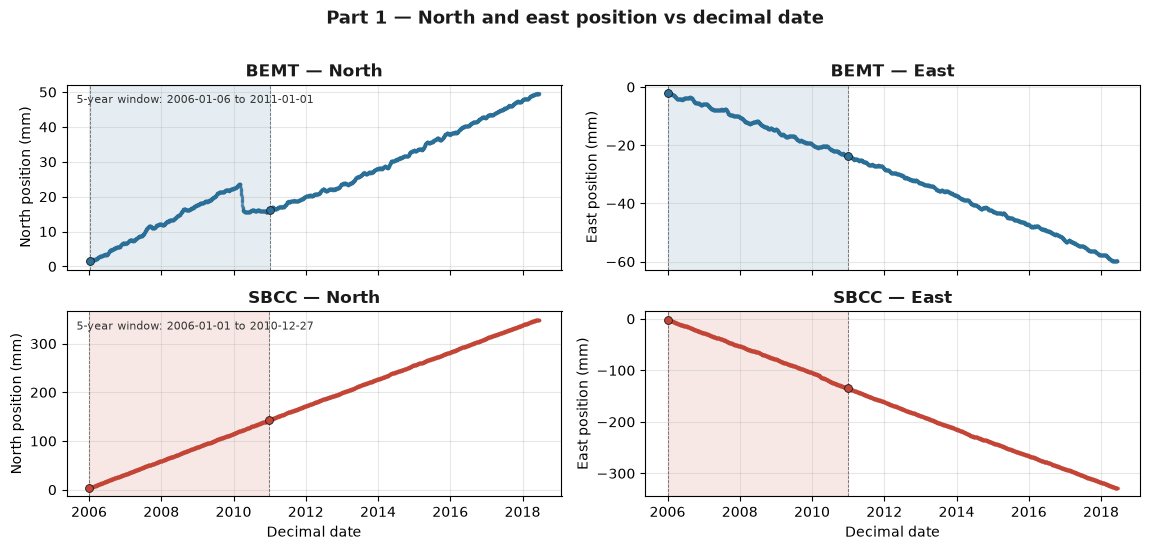

saved figures/part1_timeseries.png


In [3]:
part1_ids = ["BEMT", "SBCC"]
part1 = [
    motion_over_interval(station_series(positions, sid), sid, *WINDOWS[sid])
    for sid in part1_ids
]
plot_timeseries(
    positions,
    part1,
    "part1_timeseries.png",
    "Part 1 — North and east position vs decimal date",
)


Both stations trend up on the north plot (they are moving north) and down on the east plot (the east component is decreasing, so they are moving west). SBCC's trend is much steeper than BEMT's. BEMT's north component also has a short step near the end of the shaded window; the two-point rate uses the values at the marked endpoints, so a step like that is part of what those two points capture. The two marked points on each panel are the start and end of the window that the next section uses for the rate.


## Five-year rates

Pick a five-year interval, read the north and east position at the start and at the end, take the difference, and divide by 5 years. The completed spreadsheet uses these windows:

- BEMT: 2006-01-06 to 2011-01-01
- SBCC: 2006-01-01 to 2010-12-27

The SBCC end date is a few days shy of a round five years; both windows follow the rows used in the workbook, and both rates still divide by 5. The east–west rate in the spreadsheet is stored as a positive distance. Here the east rate is signed, so a negative value means west.


In [4]:
part1_table = show_rates_table(part1)
print()
for r in part1:
    print(
        f"{r['station']}: {r['dN']:.4f} mm north and {r['dE']:.4f} mm east "
        f"in {r['dt_years']:.4f} yr  →  "
        f"{r['rate_n']:.4f} mm/yr north, {r['rate_e']:.4f} mm/yr east, "
        f"total {r['total']:.4f} mm/yr {r['direction']} "
        f"(azimuth {r['azimuth_deg']:.1f}° from north)."
    )
    print(
        f"    (the spreadsheet divides by {YEARS_FOR_RATE:g} yr; "
        f"the decimal-date span is {r['dt_years']:.4f} yr)"
    )


Station,Window,Span (yr),ΔN (mm),ΔE (mm),North rate (mm/yr),East rate (mm/yr),Total rate (mm/yr),Direction,Azimuth (°)
BEMT,2006-01-06 to 2011-01-01,4.9863,14.8317,-21.6067,2.9663,-4.3213,5.2415,northwest,304.5
SBCC,2006-01-01 to 2010-12-27,4.9836,139.7240,-132.9670,27.9448,-26.5934,38.5762,northwest,316.4



BEMT: 14.8317 mm north and -21.6067 mm east in 4.9863 yr  →  2.9663 mm/yr north, -4.3213 mm/yr east, total 5.2415 mm/yr northwest (azimuth 304.5° from north).
    (the spreadsheet divides by 5 yr; the decimal-date span is 4.9863 yr)
SBCC: 139.7240 mm north and -132.9670 mm east in 4.9836 yr  →  27.9448 mm/yr north, -26.5934 mm/yr east, total 38.5762 mm/yr northwest (azimuth 316.4° from north).
    (the spreadsheet divides by 5 yr; the decimal-date span is 4.9836 yr)


BEMT moves about 2.97 mm/yr north and 4.32 mm/yr west, a total of 5.24 mm/yr to the northwest. SBCC moves about 27.94 mm/yr north and 26.59 mm/yr west, a total of 38.58 mm/yr, also to the northwest. Same quadrant, very different speeds.


## Combining the components into a vector

The total rate above is the Pythagorean combination of the two components. The lab also asks for that same result as a drawn vector: a guide arrow for the annual north–south movement, a guide arrow for the annual east–west movement from its tip, and the diagonal from the origin. The length of that diagonal is the horizontal speed, and its direction is the direction of motion. Both panels below use the same axis limits so the two arrow lengths can be compared by eye.


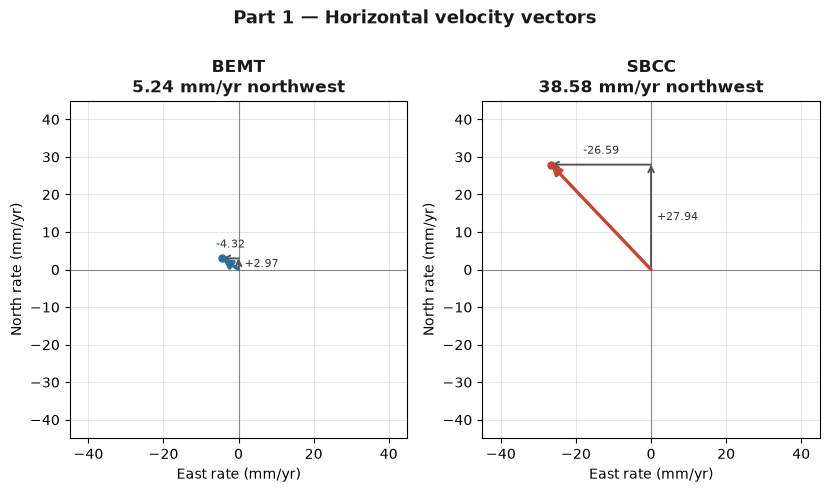

saved figures/part1_vectors.png


In [5]:
plot_vectors(
    part1,
    "part1_vectors.png",
    "Part 1 — Horizontal velocity vectors",
    scale_max=45,
)


The two arrows point the same way (northwest). SBCC's arrow is much longer. The diagonal lengths match the calculated speeds. In the NAM08 frame both sites have a northwest component, but SBCC (west of the boundary, near Mission Viejo) is moving much faster than BEMT (inland, near Twentynine Palms). They are not moving in opposite directions, and they are not moving at the same rate.

BEMT's longitude was not in the workbook, so a surveyed map of these two stations cannot be drawn from the lab files alone. The sketch below is only a schematic: a northwest–southeast boundary, SBCC on the southwest (Pacific) side, BEMT on the northeast (North American) side, with the two vectors at their computed lengths and directions. The useful part is the relative motion. From BEMT's point of view, SBCC is pulling away to the northwest; from SBCC's point of view, BEMT lags behind. Relative to each other that is right-lateral shear along a northwest–southeast boundary, even though in the NAM08 frame both arrows point the same way.


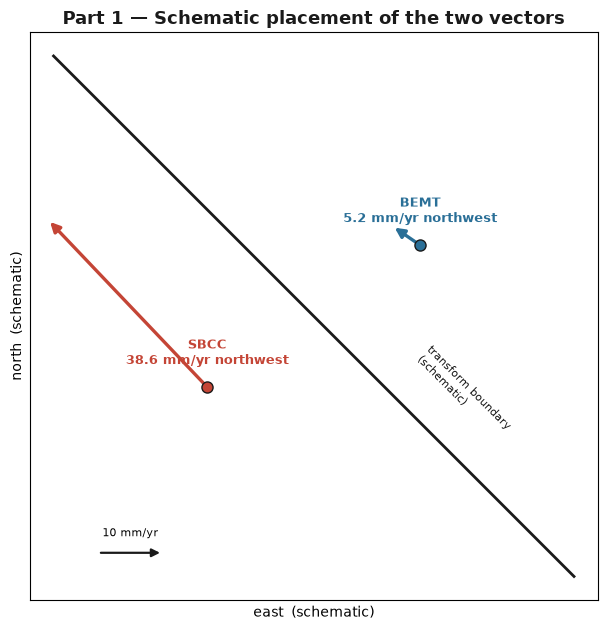

saved figures/part1_schematic_map.png


In [6]:
# Schematic only: BEMT's longitude is not in the lab workbook, so the
# station dots are placed by hand on opposite sides of a sketched fault.
# The arrows themselves use the computed Part 1 rates and are to scale.

fig, ax = plt.subplots(figsize=(7.2, 6.4))

# A NW-SE line standing in for the transform boundary.
fault_x = np.array([-22.0, 22.0])
fault_y = np.array([22.0, -22.0])
ax.plot(fault_x, fault_y, color="#1a1a1a", lw=2.0, zorder=2)
ax.text(
    8.5, -6.5, "transform boundary\n(schematic)",
    fontsize=8, color="#1a1a1a", rotation=-45, va="center",
)

# Arbitrary sketch coordinates, not map coordinates.
# SBCC: southwest of the fault (Pacific side). BEMT: northeast side.
sketch = {
    "SBCC": np.array([-9.0, -6.0]),
    "BEMT": np.array([9.0, 6.0]),
}
# 1 sketch unit = 2 mm/yr, so a 40 mm/yr arrow is 20 units long.
SKETCH_PER_MMYR = 0.5

for r in part1:
    xy = sketch[r["station"]]
    # East is +x, north is +y, matching the vector plots.
    dxy = np.array([r["rate_e"], r["rate_n"]]) * SKETCH_PER_MMYR
    color = STATION_COLORS[r["station"]]
    ax.annotate(
        "", xy=xy + dxy, xytext=xy,
        arrowprops=dict(arrowstyle="-|>", color=color, lw=2.4,
                        mutation_scale=14, shrinkA=0, shrinkB=0),
    )
    ax.plot(*xy, "o", color=color, ms=8, zorder=4, markeredgecolor="#1a1a1a")
    ax.text(
        xy[0], xy[1] + 1.6,
        f"{r['station']}\n{r['total']:.1f} mm/yr {r['direction']}",
        ha="center", va="bottom", fontsize=9, color=color, fontweight="bold",
    )

# Scale bar for the arrows (not for the made-up station spacing).
ax.annotate(
    "", xy=(-18 + 10 * SKETCH_PER_MMYR, -20), xytext=(-18, -20),
    arrowprops=dict(arrowstyle="-|>", color="#1a1a1a", lw=1.6,
                    mutation_scale=12, shrinkA=0, shrinkB=0),
)
ax.text(-18 + 5 * SKETCH_PER_MMYR, -18.6, "10 mm/yr", ha="center", fontsize=8)

ax.set_aspect("equal")
ax.set_xlim(-24, 24)
ax.set_ylim(-24, 24)
ax.set_xlabel("east  (schematic)")
ax.set_ylabel("north  (schematic)")
ax.set_title(
    "Part 1 — Schematic placement of the two vectors",
    **TITLE,
)
ax.grid(True, alpha=0.25)
# Keep ticks but make clear this is not a lon/lat map.
ax.set_xticks([])
ax.set_yticks([])
fig.tight_layout()
out = FIGDIR / "part1_schematic_map.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")


## Part 3 — Rates, neighboring stations, and earthquakes

The same measurement is now applied to three stations farther northwest along the plate boundary: CARH, CAND, and P294. In southern California the western (Pacific) side of the transform is moving northwest faster than the eastern (North American) side. The plates keep moving, but a fault is not slipping every day. Along a locked patch, friction holds the two sides together while the far-field motion continues, so stress builds until it overcomes that friction and the ground slips. That is the elastic-rebound idea, and it is why a long-term GPS rate is useful: it measures the motion that is loading the fault, not just the motion during an earthquake.

The three stations are close to one another (the workbook lists coordinates for all three). The lab again asks for north and east plots, a five-year rate in each direction, a total rate, a vector, and then those vectors placed on a map. The five-year window used in the spreadsheet for all three is 2010-01-01 to 2015-01-01.


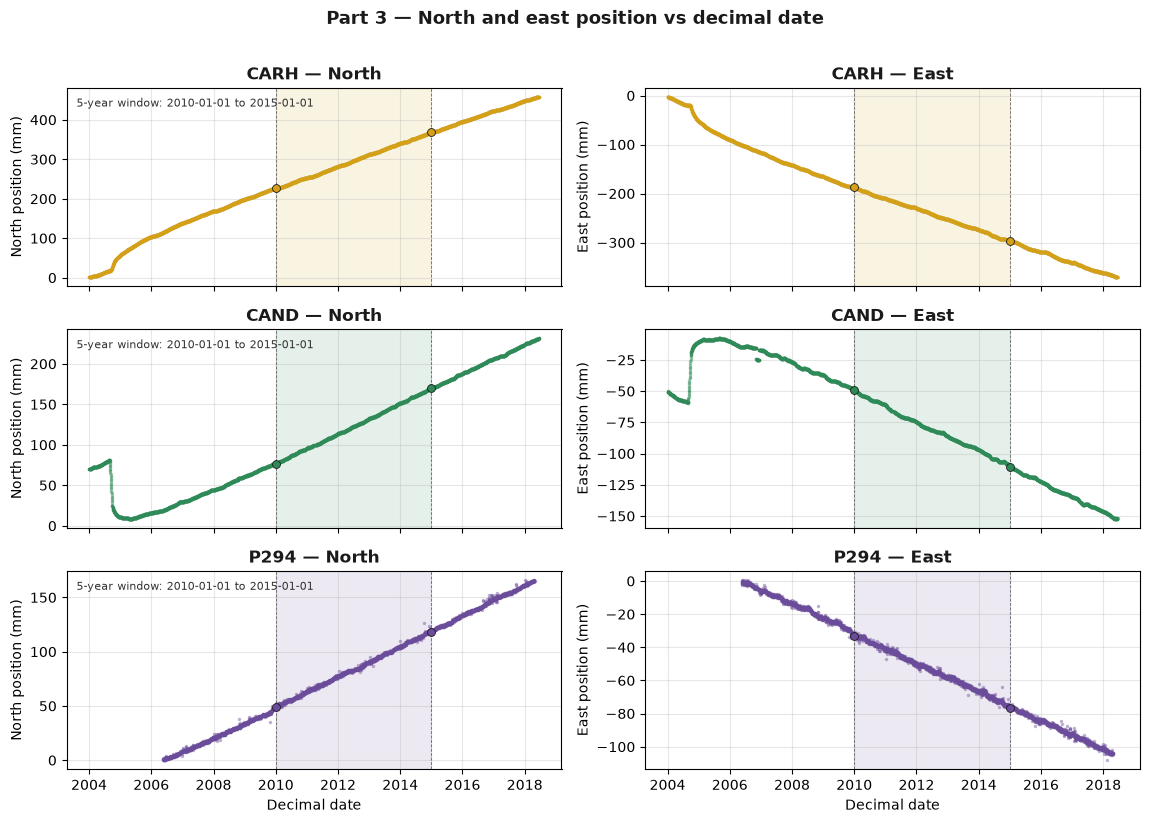

saved figures/part3_timeseries.png


In [7]:
part3_ids = ["CARH", "CAND", "P294"]
part3 = [
    motion_over_interval(station_series(positions, sid), sid, *WINDOWS[sid])
    for sid in part3_ids
]
plot_timeseries(
    positions,
    part3,
    "part3_timeseries.png",
    "Part 3 — North and east position vs decimal date",
)


All three stations again trend north and west through the shaded window. CARH has the steepest slope, then CAND, then P294. CAND also shows a large step in 2005, before the window used for the rate; inside 2010–2015 the trend is close to a straight line. P294 is a daily series rather than a 30-day average, so its points have more short-term scatter, but the multi-year trend is still clear.


Station,Window,Span (yr),ΔN (mm),ΔE (mm),North rate (mm/yr),East rate (mm/yr),Total rate (mm/yr),Direction,Azimuth (°)
CARH,2010-01-01 to 2015-01-01,5.0000,141.9680,-108.4293,28.3936,-21.6859,35.7278,northwest,322.6
CAND,2010-01-01 to 2015-01-01,5.0000,93.0683,-61.6317,18.6137,-12.3263,22.3250,northwest,326.5
P294,2010-01-01 to 2015-01-01,5.0000,69.0600,-43.4200,13.8120,-8.6840,16.3151,northwest,327.8



CARH: 28.3936 mm/yr north, -21.6859 mm/yr east, total 35.7278 mm/yr northwest (azimuth 322.6° from north).
CAND: 18.6137 mm/yr north, -12.3263 mm/yr east, total 22.3250 mm/yr northwest (azimuth 326.5° from north).
P294: 13.8120 mm/yr north, -8.6840 mm/yr east, total 16.3151 mm/yr northwest (azimuth 327.8° from north).


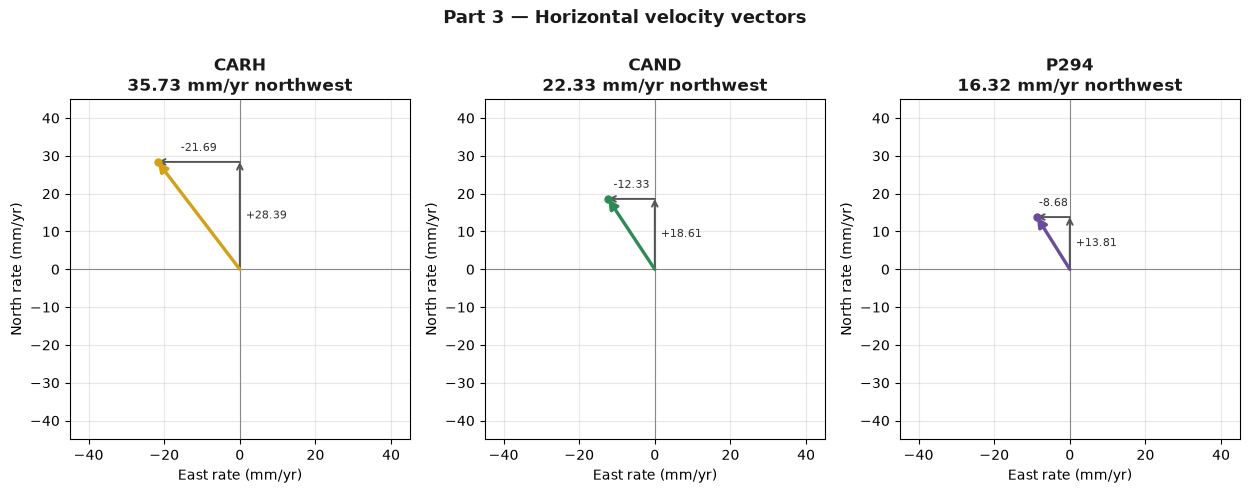

saved figures/part3_vectors.png


In [8]:
part3_table = show_rates_table(part3)
print()
for r in part3:
    print(
        f"{r['station']}: {r['rate_n']:.4f} mm/yr north, "
        f"{r['rate_e']:.4f} mm/yr east, "
        f"total {r['total']:.4f} mm/yr {r['direction']} "
        f"(azimuth {r['azimuth_deg']:.1f}° from north)."
    )

plot_vectors(
    part3,
    "part3_vectors.png",
    "Part 3 — Horizontal velocity vectors",
    scale_max=45,
)


All three arrows point northwest, like the Part 1 pair, and they have different lengths: CARH is the fastest at 35.73 mm/yr, CAND is 22.33 mm/yr, and P294 is the slowest at 16.32 mm/yr. The last lab step is to put those arrows on a map, starting at each station, with lengths in proportion to the rates. The workbook has longitude and latitude for all three of these stations, so this map can be drawn from the lab numbers. Positions are converted to a local east/north frame in kilometers using a sphere of radius 6,371 km (a conversion choice for the plot, not a number from the spreadsheet).


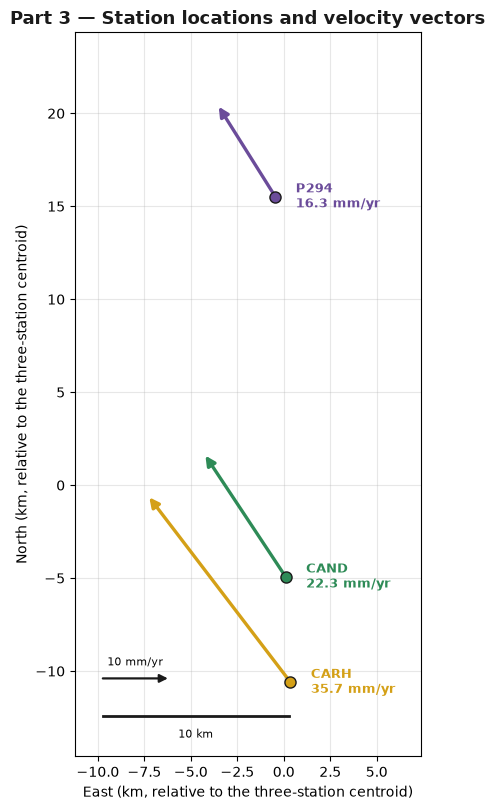

saved figures/part3_map.png

Neighboring-station distances and rate differences
(distances use a sphere of radius 6371 km):
  CARH to CAND: 5.67 km apart, total-rate difference 13.40 mm/yr, rough strain rate 2.36e-06 /yr
  CAND to P294: 20.45 km apart, total-rate difference 6.01 mm/yr, rough strain rate 2.94e-07 /yr


In [9]:
# Mean Earth radius used only to convert lon/lat to a local km frame
# for this map. It is not an input from the lab spreadsheet.
R_KM = 6371.0

coords = stations.set_index("station").loc[part3_ids]
lat0 = float(coords["latitude_deg"].mean())
lon0 = float(coords["longitude_deg"].mean())
lat0_rad = math.radians(lat0)


def to_local_km(lat, lon):
    """East and north distance from (lat0, lon0), on a sphere of radius R_KM."""
    east = (math.radians(lon - lon0) * math.cos(lat0_rad)) * R_KM
    north = math.radians(lat - lat0) * R_KM
    return east, north


# Arrow scale: 1 mm/yr is drawn as this many km on the map.
KM_PER_MMYR = 0.35  # 10 mm/yr → 3.5 km, comparable to the station spacing

fig, ax = plt.subplots(figsize=(7.4, 8.2))

xy = {}
for sid in part3_ids:
    lat = float(coords.loc[sid, "latitude_deg"])
    lon = float(coords.loc[sid, "longitude_deg"])
    xy[sid] = np.array(to_local_km(lat, lon))

for r in part3:
    sid = r["station"]
    origin = xy[sid]
    dxy = np.array([r["rate_e"], r["rate_n"]]) * KM_PER_MMYR
    color = STATION_COLORS[sid]
    ax.annotate(
        "", xy=origin + dxy, xytext=origin,
        arrowprops=dict(arrowstyle="-|>", color=color, lw=2.4,
                        mutation_scale=14, shrinkA=0, shrinkB=0),
    )
    ax.plot(*origin, "o", color=color, ms=8, zorder=4, markeredgecolor="#1a1a1a")
    # Place labels off the arrows, toward the east of each station.
    ax.text(
        origin[0] + 1.1, origin[1],
        f"{sid}\n{r['total']:.1f} mm/yr",
        ha="left", va="center", fontsize=9, color=color, fontweight="bold",
    )

# Include every station and every arrow tip in the limits, then
# place the scale bars in the lower-left corner of that frame.
tips = [
    xy[r["station"]] + np.array([r["rate_e"], r["rate_n"]]) * KM_PER_MMYR
    for r in part3
]
xs = [p[0] for p in list(xy.values()) + tips]
ys = [p[1] for p in list(xy.values()) + tips]
pad = 4.0
xmin, xmax = min(xs) - pad, max(xs) + pad + 3.0  # extra east room for labels
ymin, ymax = min(ys) - pad, max(ys) + pad
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# Scale bar for distance (10 km) and a separate scale for the arrows.
sx, sy = xmin + 1.5, ymin + 2.2
ax.plot([sx, sx + 10], [sy, sy], color="#1a1a1a", lw=2)
ax.text(sx + 5, sy - 0.7, "10 km", ha="center", va="top", fontsize=8)
ax.annotate(
    "", xy=(sx + 10 * KM_PER_MMYR, sy + 2.0), xytext=(sx, sy + 2.0),
    arrowprops=dict(arrowstyle="-|>", color="#1a1a1a", lw=1.6,
                    mutation_scale=12, shrinkA=0, shrinkB=0),
)
ax.text(sx + 5 * KM_PER_MMYR, sy + 2.7, "10 mm/yr", ha="center", fontsize=8)

ax.set_aspect("equal")
ax.set_xlabel("East (km, relative to the three-station centroid)")
ax.set_ylabel("North (km, relative to the three-station centroid)")
ax.set_title("Part 3 — Station locations and velocity vectors", **TITLE)
ax.grid(True, alpha=0.3)
fig.tight_layout()
out = FIGDIR / "part3_map.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")

# Distances and rate differences between neighboring stations,
# useful for the lab's last question about where strain is larger.
print()
print("Neighboring-station distances and rate differences")
print(f"(distances use a sphere of radius {R_KM:g} km):")
order = ["CARH", "CAND", "P294"]  # south to north
rate = {r["station"]: r for r in part3}
for a, b in zip(order, order[1:]):
    dx = xy[b][0] - xy[a][0]
    dy = xy[b][1] - xy[a][1]
    dist_km = math.hypot(dx, dy)
    dv = rate[a]["total"] - rate[b]["total"]
    # A simple 1-D strain-rate estimate: difference in speed over separation.
    # 1 mm/yr over 1 km = 1e-6 / yr.
    strain_per_yr = (dv / 1e6) / dist_km  # (mm/yr) / km  →  1/yr, since 1 km = 1e6 mm
    print(
        f"  {a} to {b}: {dist_km:.2f} km apart, "
        f"total-rate difference {dv:.2f} mm/yr, "
        f"rough strain rate {strain_per_yr:.2e} /yr"
    )


The three stations form a nearly north–south line only a few tens of kilometers long. CARH (south) is the fastest, P294 (north) is the slowest, and CAND sits in between, much closer to CARH than to P294. The lab's last question asks which pair — CARH and CAND, or CAND and P294 — is more likely to sit across a locked fault, based on how the rates change from station to station. The printed distances and rate differences are meant to make that comparison quantitative; they are not a substitute for the written answer the original lab asked for.


## Summary of the five stations

Every station in the lab moves northwest in NAM08 over its five-year window. What changes is the speed. The bar chart below puts the Part 1 and Part 3 rates on one scale.


Station,Window,Span (yr),ΔN (mm),ΔE (mm),North rate (mm/yr),East rate (mm/yr),Total rate (mm/yr),Direction,Azimuth (°)
BEMT,2006-01-06 to 2011-01-01,4.9863,14.8317,-21.6067,2.9663,-4.3213,5.2415,northwest,304.5
SBCC,2006-01-01 to 2010-12-27,4.9836,139.7240,-132.9670,27.9448,-26.5934,38.5762,northwest,316.4
CARH,2010-01-01 to 2015-01-01,5.0000,141.9680,-108.4293,28.3936,-21.6859,35.7278,northwest,322.6
CAND,2010-01-01 to 2015-01-01,5.0000,93.0683,-61.6317,18.6137,-12.3263,22.3250,northwest,326.5
P294,2010-01-01 to 2015-01-01,5.0000,69.0600,-43.4200,13.8120,-8.6840,16.3151,northwest,327.8


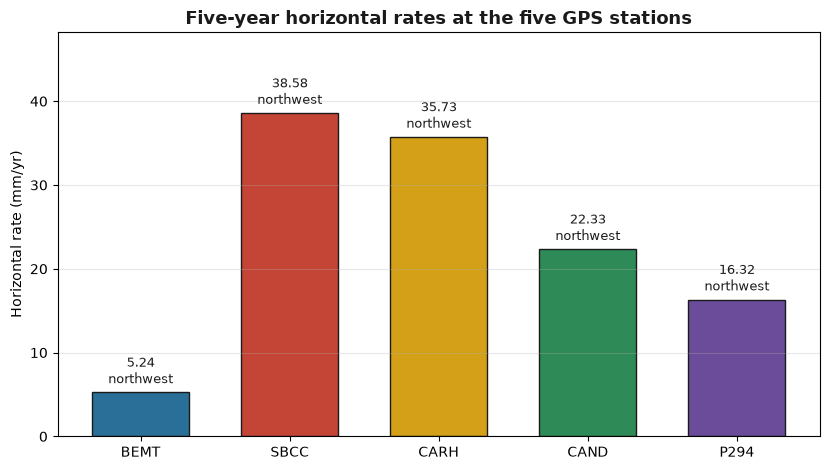

saved figures/summary_rates.png


In [10]:
all_results = part1 + part3
summary = show_rates_table(all_results)

fig, ax = plt.subplots(figsize=(8.4, 4.8))
labels = [r["station"] for r in all_results]
totals = [r["total"] for r in all_results]
colors = [STATION_COLORS[s] for s in labels]
bars = ax.bar(labels, totals, color=colors, edgecolor="#1a1a1a", width=0.65)
for bar, r in zip(bars, all_results):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.6,
        f"{r['total']:.2f}\n{r['direction']}",
        ha="center", va="bottom", fontsize=9, color="#1a1a1a",
    )
ax.set_ylabel("Horizontal rate (mm/yr)")
ax.set_ylim(0, max(totals) * 1.25)
ax.set_title("Five-year horizontal rates at the five GPS stations", **TITLE)
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
out = FIGDIR / "summary_rates.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")


## Extra (not part of the lab): two-point rate vs a linear fit

The original lab stops at the two-endpoint calculation above. This section is an optional comparison, added after the fact.

The lab rate uses two days and divides by 5. A least-squares line through every point in the same window is another way to estimate the same slope, and it uses the whole window rather than two days. If the motion is close to steady, the two numbers should agree; if a year is noisy or the endpoints sit off the trend, they will differ.


Station,Two-point total (mm/yr),Fit total (mm/yr),Difference (mm/yr),Two-point azimuth (°),Fit azimuth (°)
BEMT,5.2415,5.7702,+0.5287,304.5,310.4
SBCC,38.5762,38.4333,-0.1428,316.4,316.6
CARH,35.7278,36.0900,+0.3622,322.6,323.1
CAND,22.3250,22.0709,-0.2542,326.5,327.6
P294,16.3151,16.3817,+0.0666,327.8,328.5


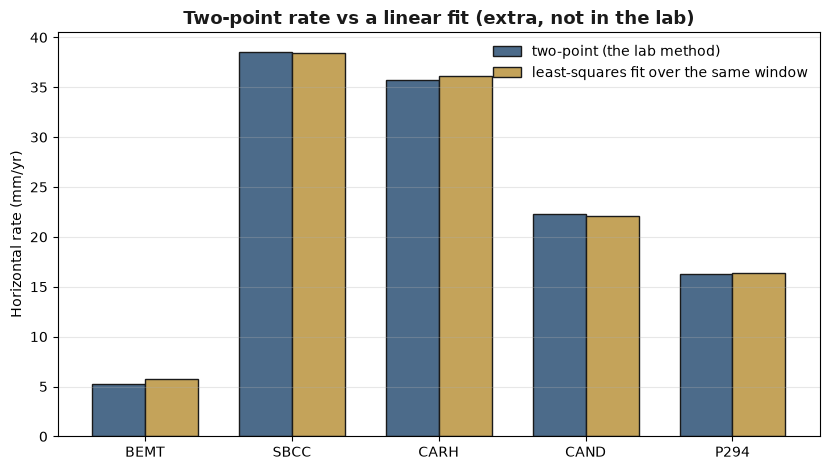

saved figures/extra_twopoint_vs_fit.png


In [11]:
def fit_rate(df, start, end):
    """Least-squares north and east rates (mm/yr) over the same window."""
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    w = df.loc[(df["date"] >= start) & (df["date"] <= end)]
    t = w["decimal_date"].to_numpy()
    vn = float(np.polyfit(t, w["north_mm"].to_numpy(), 1)[0])
    ve = float(np.polyfit(t, w["east_mm"].to_numpy(), 1)[0])
    return vn, ve, math.hypot(vn, ve)


rows = []
for r in all_results:
    df = station_series(positions, r["station"])
    vn, ve, vt = fit_rate(df, r["start"], r["end"])
    rows.append({
        "Station": r["station"],
        "Two-point total (mm/yr)": r["total"],
        "Fit total (mm/yr)": vt,
        "Difference (mm/yr)": vt - r["total"],
        "Two-point azimuth (°)": r["azimuth_deg"],
        "Fit azimuth (°)": azimuth_from_north_deg(vn, ve),
    })
fit_table = pd.DataFrame(rows)
display(
    fit_table.style.format(
        {
            "Two-point total (mm/yr)": "{:.4f}",
            "Fit total (mm/yr)": "{:.4f}",
            "Difference (mm/yr)": "{:+.4f}",
            "Two-point azimuth (°)": "{:.1f}",
            "Fit azimuth (°)": "{:.1f}",
        }
    ).hide(axis="index")
)

fig, ax = plt.subplots(figsize=(8.4, 4.8))
x = np.arange(len(rows))
w = 0.36
twopoint = [r["Two-point total (mm/yr)"] for r in rows]
fits = [r["Fit total (mm/yr)"] for r in rows]
ax.bar(x - w / 2, twopoint, width=w, color="#4C6B8A", edgecolor="#1a1a1a",
       label="two-point (the lab method)")
ax.bar(x + w / 2, fits, width=w, color="#C4A35A", edgecolor="#1a1a1a",
       label="least-squares fit over the same window")
ax.set_xticks(x)
ax.set_xticklabels([r["Station"] for r in rows])
ax.set_ylabel("Horizontal rate (mm/yr)")
ax.set_title("Two-point rate vs a linear fit (extra, not in the lab)", **TITLE)
ax.legend(frameon=False)
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
out = FIGDIR / "extra_twopoint_vs_fit.png"
fig.savefig(out, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()
print(f"saved {out}")


## Check against the Excel workbook

The next cell loads `data/excel_reference.xlsx` with `openpyxl` (`data_only=True`). That small file holds the 5-year difference, rate, and total-rate values stored in the completed lab spreadsheet. Each assertion requires the relative difference to be at most $10^{-6}$. If this cell runs without error, the Python results have reproduced those spreadsheet values.

The spreadsheet stores the east difference as an absolute value, so the check compares `abs(ΔE)` and `abs(v_E)` to those cells. The signed components computed above keep the direction.


In [12]:
from openpyxl import load_workbook

def assert_close(name, got, expected, rtol=1e-6):
    got = float(got)
    expected = float(expected)
    rel = abs(got - expected) / abs(expected) if expected != 0 else abs(got)
    assert rel <= rtol, (
        f"{name}: got {got}, expected {expected}, relative error {rel:.3e}"
    )
    print(f"ok  {name}: {got}   (relative error {rel:.2e})")


wb = load_workbook(DATADIR / "excel_reference.xlsx", data_only=True)
ws = wb["rates"]
headers = [cell.value for cell in ws[1]]
excel = {}
for row in ws.iter_rows(min_row=2, values_only=True):
    rec = dict(zip(headers, row))
    excel[rec["station"]] = rec
wb.close()

computed = {r["station"]: r for r in all_results}

for sid in ["BEMT", "SBCC", "CAND", "CARH", "P294"]:
    got, exp = computed[sid], excel[sid]
    assert got["start"] == exp["interval_start"], (
        f"{sid} start date: {got['start']} vs {exp['interval_start']}"
    )
    assert got["end"] == exp["interval_end"], (
        f"{sid} end date: {got['end']} vs {exp['interval_end']}"
    )
    assert_close(f"{sid} ΔN (mm)", got["dN"], exp["excel_north_difference_mm"])
    assert_close(
        f"{sid} |ΔE| (mm)", abs(got["dE"]), exp["excel_east_difference_mm"]
    )
    assert_close(
        f"{sid} north rate (mm/yr)",
        got["rate_n"],
        exp["excel_north_rate_mm_per_yr"],
    )
    assert_close(
        f"{sid} |east rate| (mm/yr)",
        abs(got["rate_e"]),
        exp["excel_east_rate_mm_per_yr"],
    )
    assert_close(
        f"{sid} total rate (mm/yr)",
        got["total"],
        exp["excel_total_rate_mm_per_yr"],
    )

print()
print("All checks passed: Python results match the Excel workbook to 1e-6 relative.")


ok  BEMT ΔN (mm): 14.831666666666699   (relative error 1.92e-15)
ok  BEMT |ΔE| (mm): 21.606666666666673   (relative error 1.64e-16)
ok  BEMT north rate (mm/yr): 2.9663333333333397   (relative error 2.25e-15)
ok  BEMT |east rate| (mm/yr): 4.321333333333334   (relative error 4.11e-16)
ok  BEMT total rate (mm/yr): 5.241474527480055   (relative error 8.47e-16)
ok  SBCC ΔN (mm): 139.72399999999968   (relative error 2.24e-15)
ok  SBCC |ΔE| (mm): 132.96699999999967   (relative error 2.57e-15)
ok  SBCC north rate (mm/yr): 27.944799999999937   (relative error 2.29e-15)
ok  SBCC |east rate| (mm/yr): 26.593399999999935   (relative error 2.40e-15)
ok  SBCC total rate (mm/yr): 38.576168428188836   (relative error 2.21e-15)
ok  CAND ΔN (mm): 93.0683333333333   (relative error 7.63e-16)
ok  CAND |ΔE| (mm): 61.631666666666696   (relative error 4.61e-16)
ok  CAND north rate (mm/yr): 18.61366666666666   (relative error 5.73e-16)
ok  CAND |east rate| (mm/yr): 12.32633333333334   (relative error 7.21e-16)